# Prepaid Electricity Meter Recharge Analysis (Bangladesh)

**Author:** Shahriar Mazid  
**Tools:** Python (pandas, matplotlib, seaborn, SciPy), Excel

This is my first data analysis project in Python. I work at a prepaid smart meter company, so I wanted to practise on the kind of data I see at work: customers recharging their prepaid electricity meters.

> **Note:** The dataset is **synthetic** (made with `generate_data.py`). It looks like real recharge data but has no real customer information.

## Questions
1. How does recharge spending change through the year?
2. Which payment channels do customers use most?
3. Do urban customers spend more than rural customers?
4. Are there any unusual recharges that should be checked?

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_style('whitegrid')

# colours for the charts
BLUE = '#2a78d6'
ORANGE = '#eb6834'
GREY = '#8c8b86'

## 1. Load the data

In [2]:
df = pd.read_csv('meter_recharges_raw.csv')
print(df.shape)
df.head()

(25914, 10)


,transaction_id,customer_id,recharge_date,district,utility,area_type,tariff,payment_channel,recharge_amount_bdt,units_kwh
0,TXN021604,C0501,2025-04-07,Jessore,WZPDCL,Rural,Residential,bKash,210.0,23.7
1,TXN014334,C0334,2025-08-19,Dhaka,DESCO,Urban,Residential,bKash,230.0,26.6
2,TXN018977,C0440,2025-05-25,Dhaka,DESCO,Urban,Residential,Nagad,140.0,15.9
3,TXN022171,C0513,2025-11-26,Sylhet,BPDB,Urban,Residential,Rocket,190.0,22.4
4,TXN022319,C0517,2025-04-15,Narayanganj,DPDC,Urban,Residential,Rocket,320.0,33.8


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 25914 entries, 0 to 25913
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   transaction_id       25914 non-null  str    
 1   customer_id          25914 non-null  str    
 2   recharge_date        25914 non-null  str    
 3   district             25914 non-null  str    
 4   utility              25914 non-null  str    
 5   area_type            25914 non-null  str    
 6   tariff               25914 non-null  str    
 7   payment_channel      25804 non-null  str    
 8   recharge_amount_bdt  25843 non-null  float64
 9   units_kwh            25823 non-null  float64
dtypes: float64(2), str(8)
memory usage: 2.0 MB


In [4]:
# check missing values
df.isnull().sum()

transaction_id           0
customer_id              0
recharge_date            0
district                 0
utility                  0
area_type                0
tariff                   0
payment_channel        110
recharge_amount_bdt     71
units_kwh               91
dtype: int64

In [5]:
# check duplicates
df.duplicated().sum()

np.int64(85)

In [6]:
# district names look messy
df['district'].unique()

<StringArray>
[     'Jessore',        'Dhaka',       'Sylhet',  'Narayanganj',
       'Khulna',   'Mymensingh',      'Comilla',     'Rajshahi',
      'Rangpur',      'Gazipur',      'Cumilla',       'SYLHET',
        'dhaka', ' Narayanganj',       ' Dhaka',      ' Sylhet',
  'Mymensingh ',     ' Jessore',       'Dhaka ',  'NARAYANGANJ',
   'MYMENSINGH',      'Khulna ',        'DHAKA',      'gazipur',
    'Rajshahi ',      'RANGPUR',     'Gazipur ',  'narayanganj',
      'GAZIPUR', 'Narayanganj ',  ' Mymensingh',      ' Khulna',
      'rangpur',     'RAJSHAHI',     'rajshahi',       'KHULNA',
       'khulna',      'jessore',    ' Rajshahi',     ' Rangpur',
      'JESSORE',     'Jessore ',     'Rangpur ',      'Sylhet ',
     ' Gazipur',       'sylhet',   'mymensingh']
Length: 47, dtype: str

In [7]:
df['recharge_amount_bdt'].describe()

count    25843.000000
mean       267.680223
std        226.833834
min       -340.000000
25%        140.000000
50%        210.000000
75%        330.000000
max       9520.000000
Name: recharge_amount_bdt, dtype: float64

**Problems I found:**
- 85 duplicate rows
- Dates are in two formats (`2025-03-14` and `14/03/2025`)
- District names have extra spaces and different cases, and Comilla is also written as Cumilla
- Some missing values
- Some amounts are 0 or negative, which is not possible for a recharge

## 2. Data cleaning

In [8]:
# remove duplicates
df = df.drop_duplicates()
print(df.shape)

(25829, 10)


In [9]:
# fix dates - convert both formats
date1 = pd.to_datetime(df['recharge_date'], format='%Y-%m-%d', errors='coerce')
date2 = pd.to_datetime(df['recharge_date'], format='%d/%m/%Y', errors='coerce')
df['recharge_date'] = date1.fillna(date2)

df['recharge_date'].isnull().sum()

np.int64(0)

In [10]:
# fix district names
df['district'] = df['district'].str.strip().str.title()
df['district'] = df['district'].replace('Cumilla', 'Comilla')
df['district'].unique()

<StringArray>
[    'Jessore',       'Dhaka',      'Sylhet', 'Narayanganj',      'Khulna',
  'Mymensingh',     'Comilla',    'Rajshahi',     'Rangpur',     'Gazipur']
Length: 10, dtype: str

In [11]:
# remove missing, zero and negative amounts
df = df[df['recharge_amount_bdt'] > 0]

# missing payment channel -> Unknown
df['payment_channel'] = df['payment_channel'].fillna('Unknown')

# missing units -> drop these rows (only a small number)
df = df.dropna(subset=['units_kwh'])

df.isnull().sum()

transaction_id         0
customer_id            0
recharge_date          0
district               0
utility                0
area_type              0
tariff                 0
payment_channel        0
recharge_amount_bdt    0
units_kwh              0
dtype: int64

In [12]:
# new columns
df['month'] = df['recharge_date'].dt.month
df['month_name'] = df['recharge_date'].dt.strftime('%b')
df['price_per_kwh'] = df['recharge_amount_bdt'] / df['units_kwh']

print(df.shape)
df.to_csv('meter_recharges_clean.csv', index=False)

(25649, 13)


## 3. Monthly trend

In [13]:
monthly = df.groupby(['month', 'month_name'])['recharge_amount_bdt'].sum().reset_index()
monthly

,month,month_name,recharge_amount_bdt
0,1,Jan,443180.0
1,2,Feb,446900.0
2,3,Mar,553550.0
3,4,Apr,667990.0
4,5,May,737150.0
5,6,Jun,682660.0
6,7,Jul,646380.0
7,8,Aug,623860.0
8,9,Sep,592200.0
9,10,Oct,573070.0


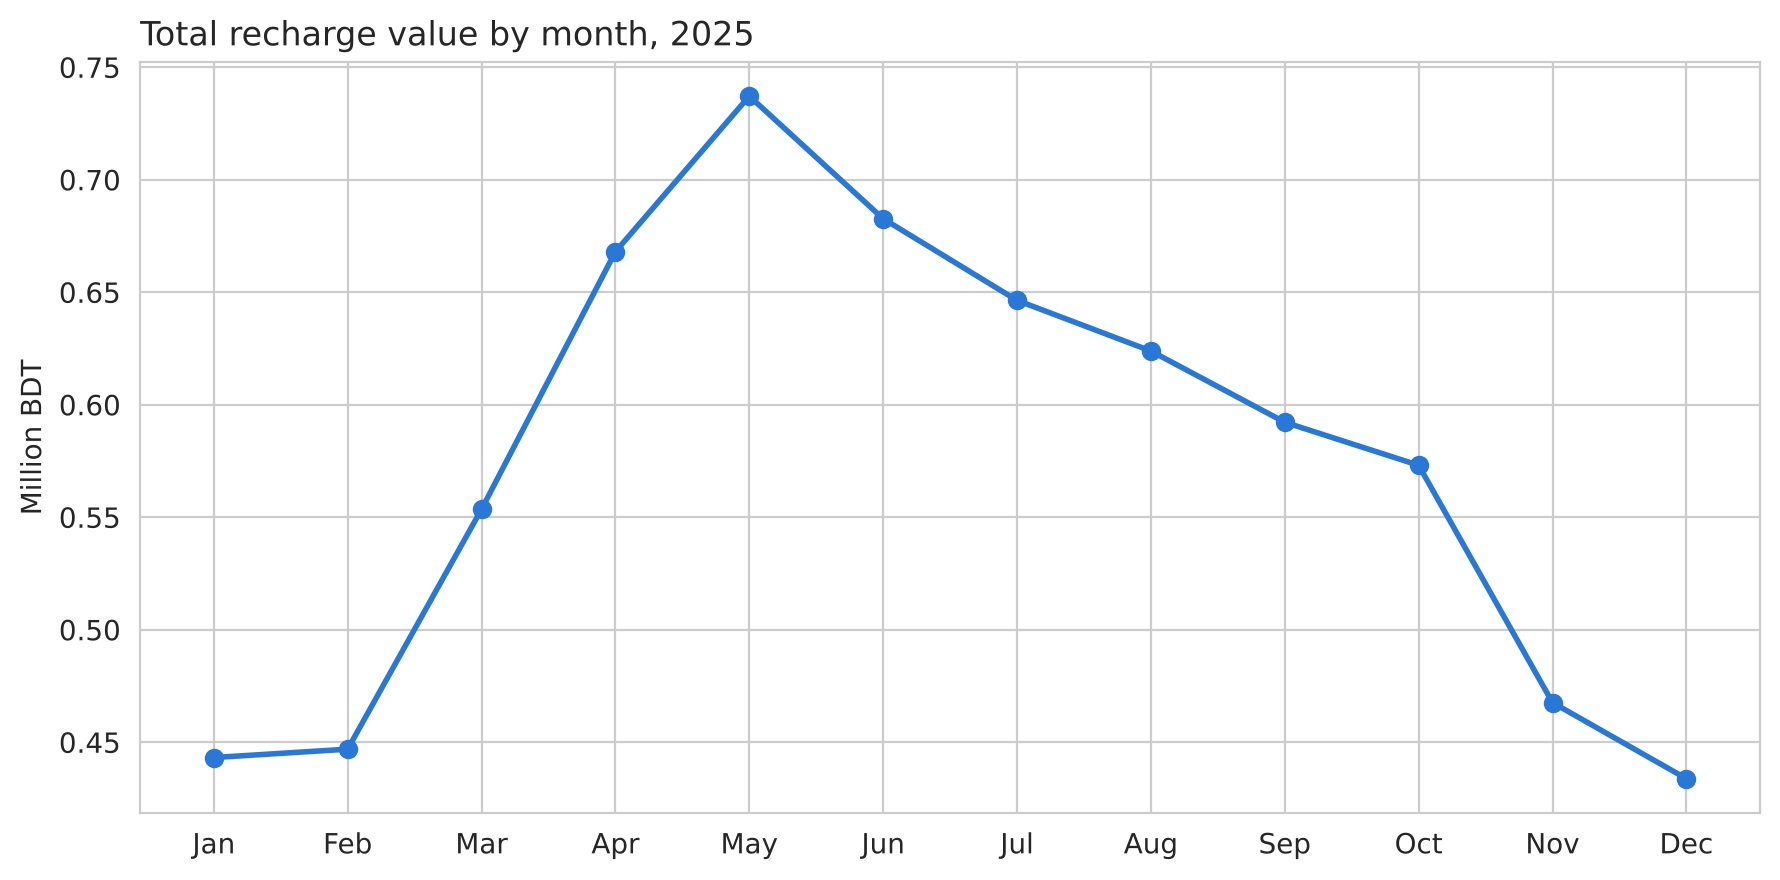

In [14]:
plt.figure(figsize=(9, 4.5))
plt.plot(monthly['month_name'], monthly['recharge_amount_bdt'] / 1000000, color=BLUE, linewidth=2, marker='o')
plt.title('Total recharge value by month, 2025', loc='left')
plt.ylabel('Million BDT')
plt.tight_layout()
plt.savefig('01_monthly_trend.png', dpi=150)
plt.show()

Recharges go up from March, are highest in **May**, and are lowest in December and January. This makes sense because people use more fans and ACs in summer.

## 4. Payment channels

In [15]:
channels = df['payment_channel'].value_counts(normalize=True) * 100
channels = channels.round(1)
channels

payment_channel
bKash            41.1
Nagad            23.4
Vending Point    18.8
Rocket            9.7
Bank Card         6.6
Unknown           0.4
Name: proportion, dtype: float64

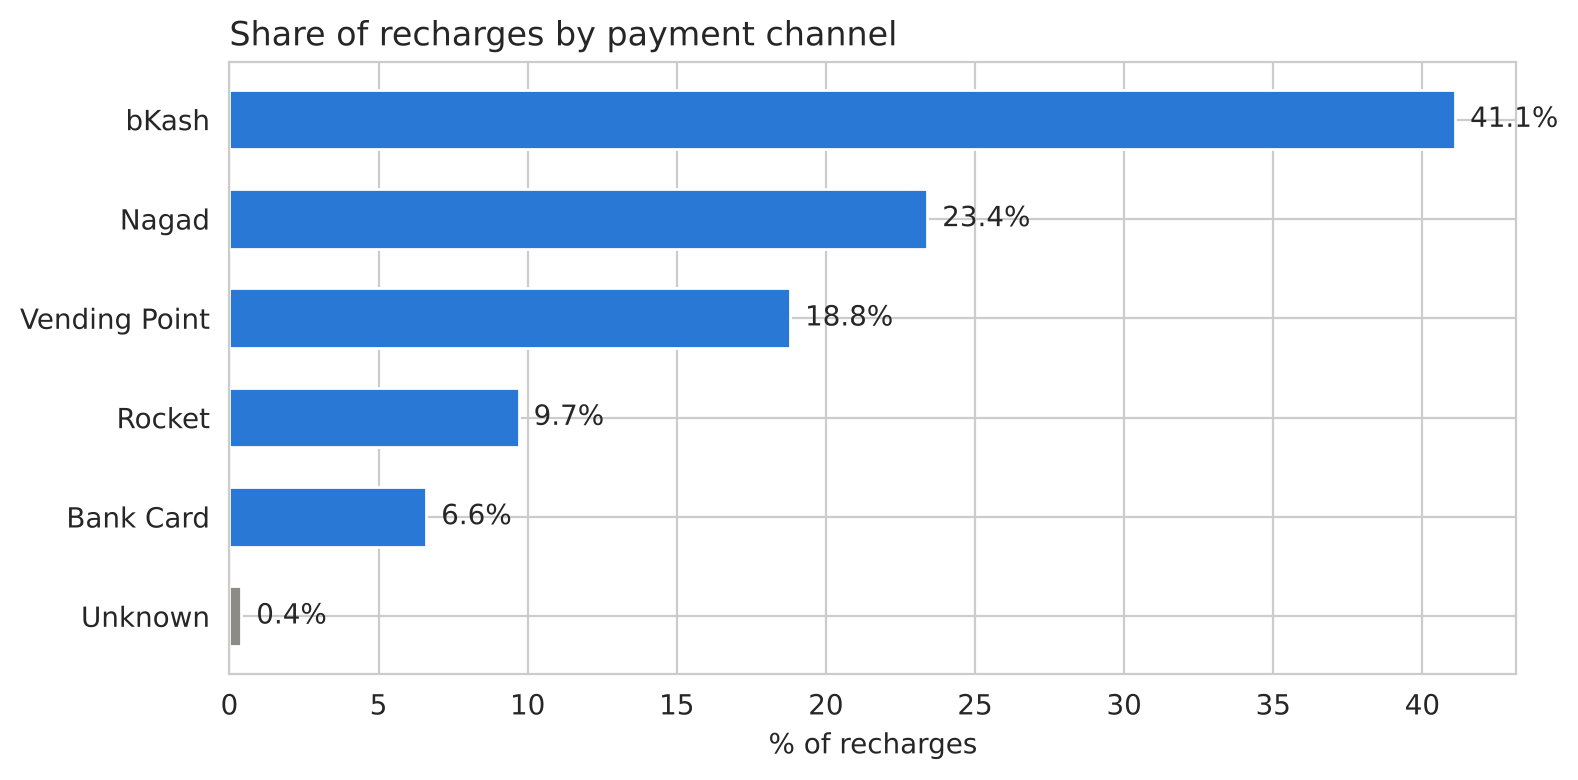

In [16]:
plt.figure(figsize=(8, 4))
colors = [GREY if c == 'Unknown' else BLUE for c in channels.index]
plt.barh(channels.index, channels.values, color=colors, height=0.6)
plt.gca().invert_yaxis()
for i, v in enumerate(channels.values):
    plt.text(v + 0.5, i, str(v) + '%', va='center')
plt.title('Share of recharges by payment channel', loc='left')
plt.xlabel('% of recharges')
plt.tight_layout()
plt.savefig('02_payment_channels.png', dpi=150)
plt.show()

bKash is the most used channel (about 41%), then Nagad (about 23%). Together, mobile wallets are nearly two-thirds of all recharges. Vending points are still used for about 1 in 5 recharges.

## 5. Districts

In [17]:
district = df.groupby(['district', 'area_type']).agg(
    customers=('customer_id', 'nunique'),
    total_bdt=('recharge_amount_bdt', 'sum'),
    avg_recharge=('recharge_amount_bdt', 'mean')
).reset_index()
district = district.sort_values('total_bdt', ascending=False).round(1)
district

,district,area_type,customers,total_bdt,avg_recharge
1,Dhaka,Urban,138,1761740.0,296.9
2,Gazipur,Urban,54,702550.0,296.7
4,Khulna,Urban,64,697650.0,255.8
6,Narayanganj,Urban,52,668550.0,289.5
9,Sylhet,Urban,55,652050.0,290.3
5,Mymensingh,Rural,57,555820.0,225.2
8,Rangpur,Rural,52,513940.0,226.1
0,Comilla,Rural,55,475910.0,202.0
7,Rajshahi,Urban,34,469140.0,346.5
3,Jessore,Rural,39,371000.0,229.9


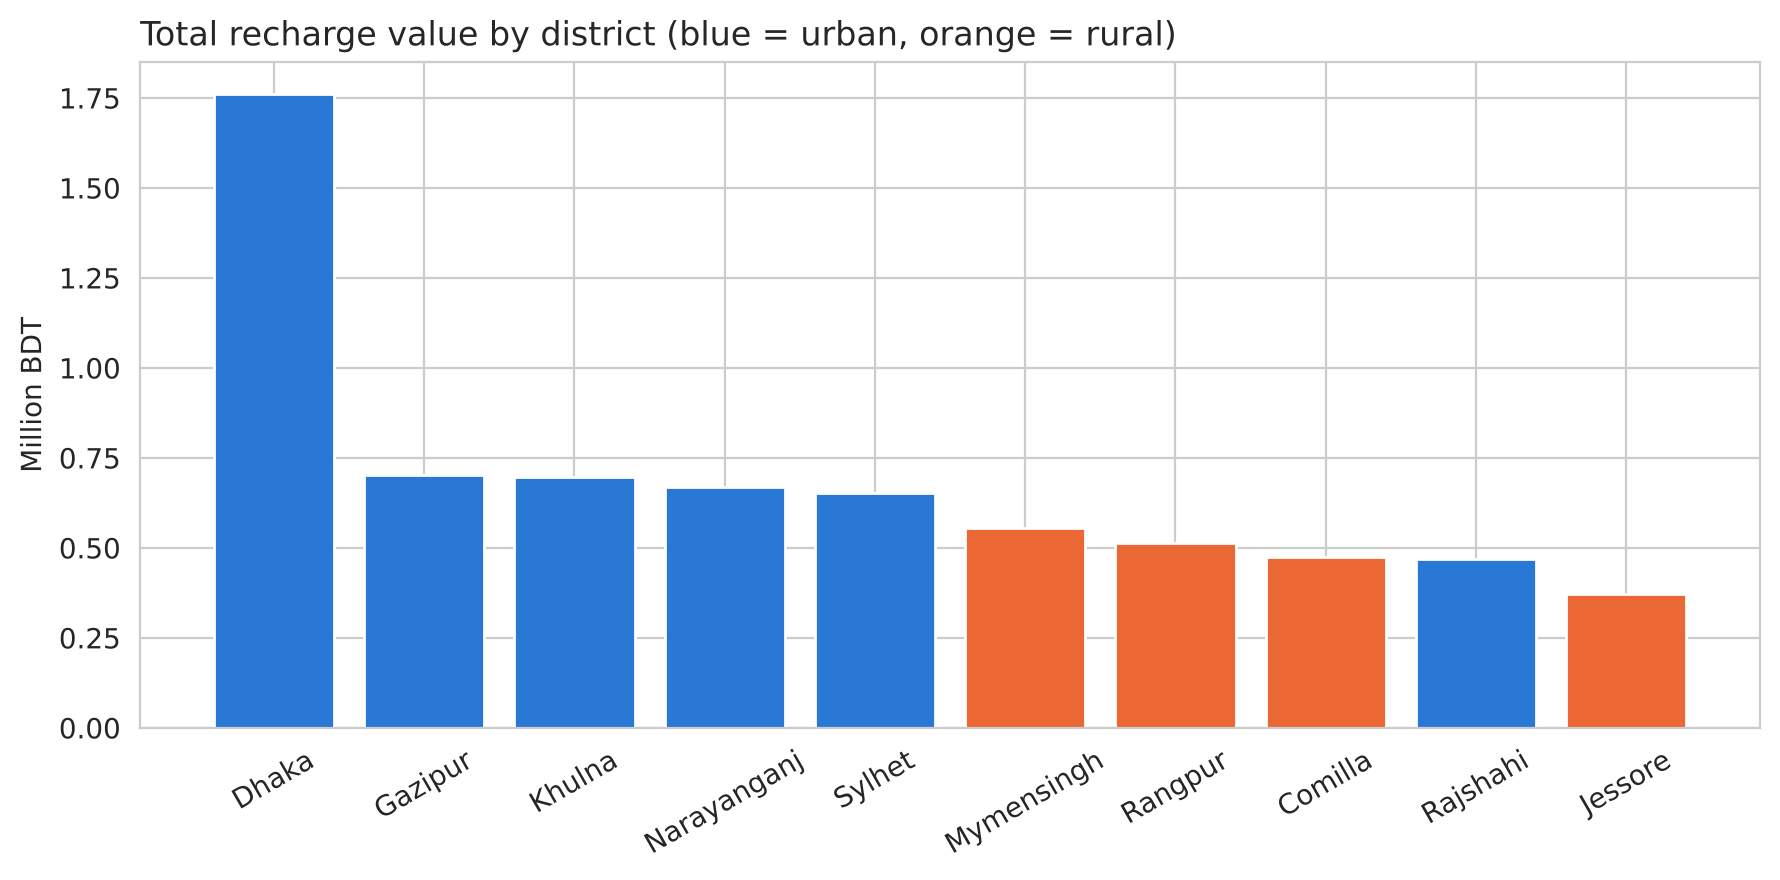

In [18]:
plt.figure(figsize=(9, 4.5))
colors = [BLUE if a == 'Urban' else ORANGE for a in district['area_type']]
plt.bar(district['district'], district['total_bdt'] / 1000000, color=colors)
plt.title('Total recharge value by district (blue = urban, orange = rural)', loc='left')
plt.ylabel('Million BDT')
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig('03_district_totals.png', dpi=150)
plt.show()

Dhaka is by far the biggest district because it has the most customers. Rural districts (orange) are in the lower half. Rajshahi is urban but is also low because it has the fewest customers in the data.

## 6. Do urban customers spend more than rural customers?
First I calculate each customer's **average monthly spending**, and I only use residential customers so that commercial customers don't affect the result.

- **H0:** urban and rural customers spend the same on average
- **H1:** they spend differently

I use a t-test. I set `equal_var=False` (Welch's t-test) because the two groups may have different spreads.

In [19]:
residential = df[df['tariff'] == 'Residential']

monthly_spend = residential.groupby(['customer_id', 'area_type', 'month'])['recharge_amount_bdt'].sum().reset_index()
customer_avg = monthly_spend.groupby(['customer_id', 'area_type'])['recharge_amount_bdt'].mean().reset_index()

urban = customer_avg[customer_avg['area_type'] == 'Urban']['recharge_amount_bdt']
rural = customer_avg[customer_avg['area_type'] == 'Rural']['recharge_amount_bdt']

print('Urban customers:', len(urban), ' average monthly spend:', round(urban.mean()), 'BDT')
print('Rural customers:', len(rural), ' average monthly spend:', round(rural.mean()), 'BDT')

Urban customers: 326  average monthly spend: 847 BDT
Rural customers: 165  average monthly spend: 672 BDT


In [20]:
t_stat, p_value = stats.ttest_ind(urban, rural, equal_var=False)
print('t-statistic:', round(t_stat, 2))
print('p-value:', p_value)

if p_value < 0.05:
    print('Reject H0 - urban and rural spending is different')
else:
    print('Fail to reject H0')

t-statistic: 6.36
p-value: 5.032057493842775e-10
Reject H0 - urban and rural spending is different


/tmp/ipykernel_157/3391878298.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=customer_avg, x='area_type', y='recharge_amount_bdt',


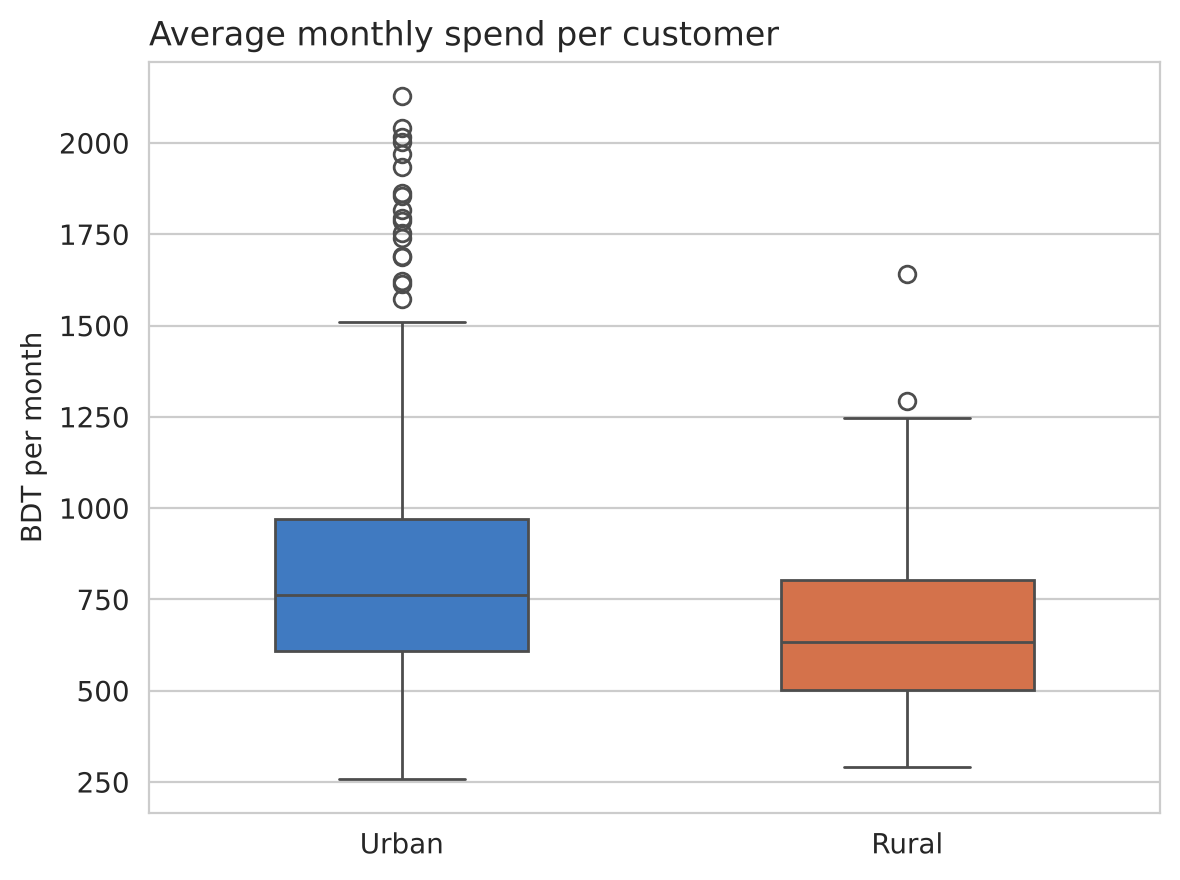

In [21]:
plt.figure(figsize=(6, 4.5))
sns.boxplot(data=customer_avg, x='area_type', y='recharge_amount_bdt',
            palette={'Urban': BLUE, 'Rural': ORANGE}, width=0.5)
plt.title('Average monthly spend per customer', loc='left')
plt.xlabel('')
plt.ylabel('BDT per month')
plt.tight_layout()
plt.savefig('04_urban_vs_rural.png', dpi=150)
plt.show()

The p-value is much smaller than 0.05, so the difference is statistically significant. Urban residential customers spend about BDT 175 more per month than rural ones on average.

## 7. Unusual recharges
For a normal recharge, the price per kWh should be almost the same every time. If someone pays a lot of money but gets very few units, something may be wrong (data entry error, vendor problem or tampering).

**Rule:** flag a recharge if its price per kWh is more than 50% higher or lower than the median.

In [22]:
median_price = df['price_per_kwh'].median()
print('Median price per kWh:', round(median_price, 2), 'BDT')

df['flagged'] = (df['price_per_kwh'] > median_price * 1.5) | (df['price_per_kwh'] < median_price * 0.5)
print('Flagged recharges:', df['flagged'].sum())

Median price per kWh: 8.63 BDT
Flagged recharges: 45


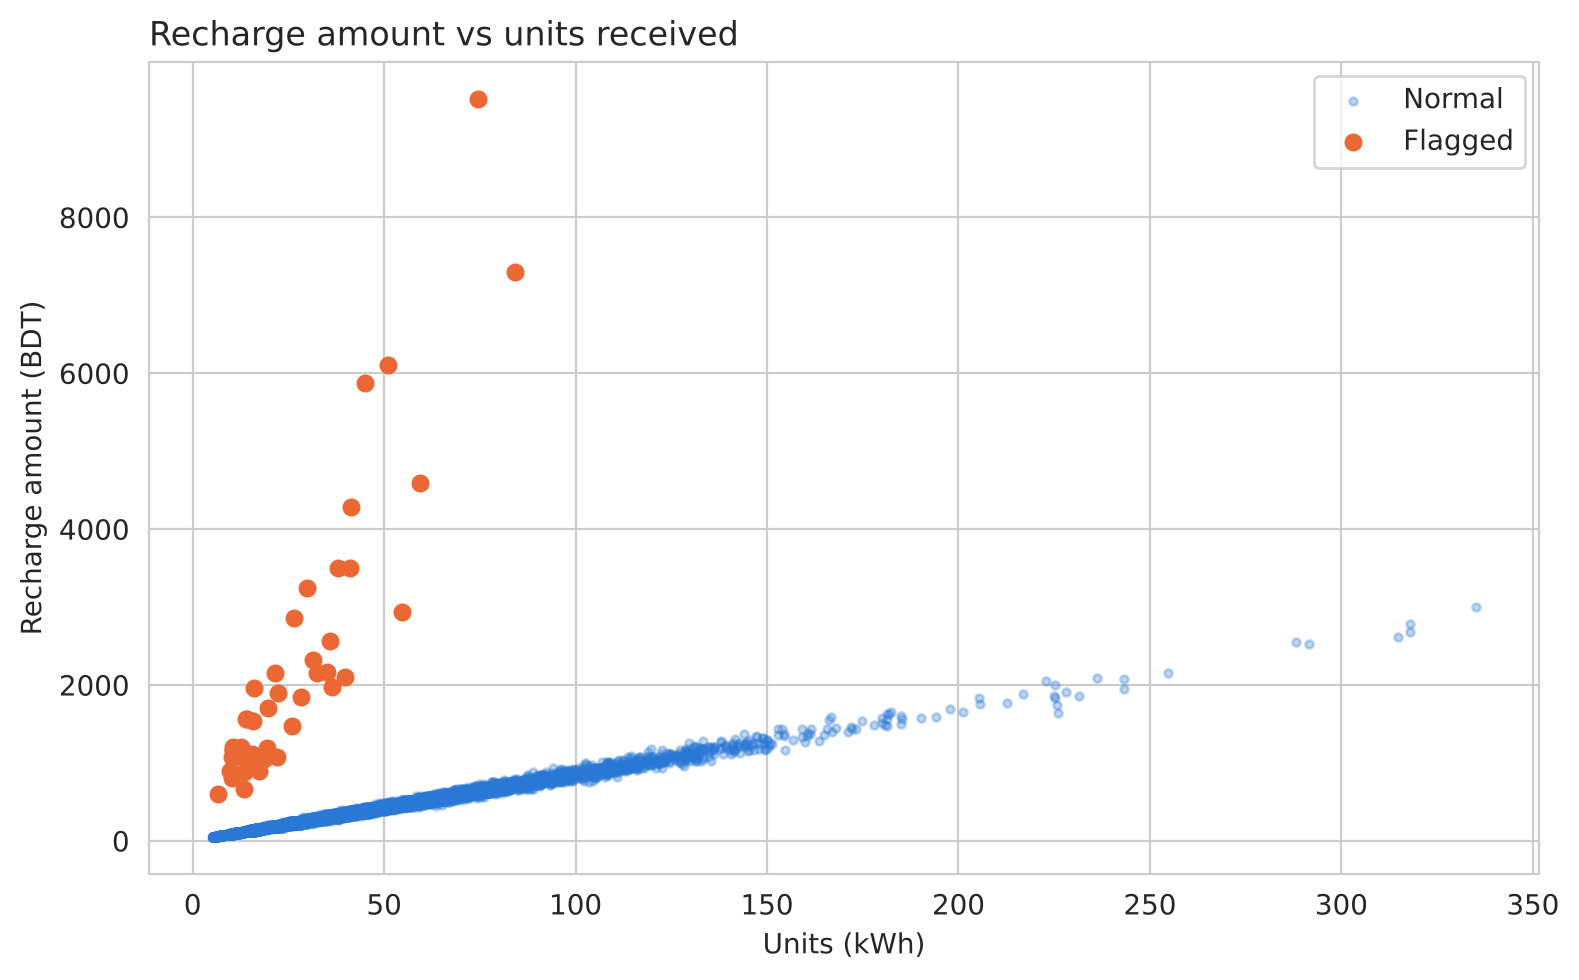

In [23]:
plt.figure(figsize=(8, 5))
normal = df[df['flagged'] == False]
flagged = df[df['flagged'] == True]
plt.scatter(normal['units_kwh'], normal['recharge_amount_bdt'], s=8, alpha=0.3, color=BLUE, label='Normal')
plt.scatter(flagged['units_kwh'], flagged['recharge_amount_bdt'], s=30, color=ORANGE, label='Flagged')
plt.title('Recharge amount vs units received', loc='left')
plt.xlabel('Units (kWh)')
plt.ylabel('Recharge amount (BDT)')
plt.legend()
plt.tight_layout()
plt.savefig('05_flagged_recharges.png', dpi=150)
plt.show()

In [24]:
flagged_list = flagged[['transaction_id', 'customer_id', 'recharge_date', 'district', 'payment_channel',
                        'recharge_amount_bdt', 'units_kwh', 'price_per_kwh']]
flagged_list = flagged_list.sort_values('recharge_amount_bdt', ascending=False)
flagged_list.head(10)

,transaction_id,customer_id,recharge_date,district,payment_channel,recharge_amount_bdt,units_kwh,price_per_kwh
7249,TXN013777,C0321,2025-10-11,Rangpur,Rocket,9520.0,74.5,127.785235
7234,TXN011967,C0282,2025-04-07,Narayanganj,Vending Point,7300.0,84.2,86.698337
5370,TXN007131,C0168,2025-05-13,Dhaka,Nagad,6110.0,50.9,120.039293
18018,TXN025540,C0594,2025-05-26,Narayanganj,bKash,5880.0,44.9,130.957684
18042,TXN005803,C0140,2025-03-09,Sylhet,bKash,4590.0,59.4,77.272727
18549,TXN014974,C0348,2025-12-15,Dhaka,Vending Point,4290.0,41.4,103.623188
20383,TXN024459,C0569,2025-07-03,Comilla,Vending Point,3500.0,41.2,84.951456
2230,TXN020158,C0465,2025-04-05,Sylhet,Nagad,3500.0,37.9,92.348285
15829,TXN003978,C0095,2025-05-16,Mymensingh,Vending Point,3240.0,29.9,108.361204
23800,TXN025462,C0592,2025-01-10,Khulna,bKash,2940.0,54.7,53.747715


Most recharges sit on a straight line (amount and units go up together). The flagged ones are far above the line: customers paid a lot but received very few units. These should be checked with the vendor, but a flag doesn't prove fraud.

## 8. Save results to Excel

In [25]:
with pd.ExcelWriter('recharge_analysis_summary.xlsx', engine='openpyxl') as writer:
    monthly.to_excel(writer, sheet_name='Monthly', index=False)
    channels.to_excel(writer, sheet_name='Channels')
    district.to_excel(writer, sheet_name='Districts', index=False)
    flagged_list.to_excel(writer, sheet_name='Flagged', index=False)

    # make columns wider
    for sheet in writer.sheets.values():
        for col in sheet.columns:
            sheet.column_dimensions[col[0].column_letter].width = 18

print('Excel file saved')

Excel file saved


## 9. Conclusion
1. Recharge spending is **seasonal**: highest in May, lowest in winter.
2. **bKash and Nagad** are the main payment channels.
3. **Urban residential customers spend more** than rural ones, and the t-test shows the difference is significant.
4. A simple price-per-kWh rule found a small number of **unusual recharges** worth checking.

## What I want to try next
- Predict next month's recharge demand with a regression model
- Try a better method for finding unusual recharges
- Use real data, if possible